In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

url = "https://raw.githubusercontent.com/FusRaDa/biot670i_capstone_vaccination_project/main/app/data/cases_coverage_ms.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (1163, 18)

Column names:
['year', 'state', 'measles_cases', 'mumps_cases', 'pertussis_cases', 'measles_coverage_pct', 'measles_n', 'measles_n_vaccinated', 'mumps_coverage_pct', 'mumps_n', 'mumps_n_vaccinated', 'pertussis_coverage_pct', 'pertussis_n', 'pertussis_n_vaccinated', 'population', 'measles_cases_per_100k', 'mumps_cases_per_100k', 'pertussis_cases_per_100k']

First five rows:


,year,state,measles_cases,mumps_cases,pertussis_cases,measles_coverage_pct,measles_n,measles_n_vaccinated,mumps_coverage_pct,mumps_n,mumps_n_vaccinated,pertussis_coverage_pct,pertussis_n,pertussis_n_vaccinated,population,measles_cases_per_100k,mumps_cases_per_100k,pertussis_cases_per_100k
0,1995,AK,NaN,13.0,1.0,89.86,194.0,177.0,89.86,194.0,177.0,77.58,194.0,159.0,604412.0,NaN,2.150851,0.165450
1,1996,AK,63.0,3.0,4.0,84.55,260.0,225.0,84.55,260.0,225.0,78.25,260.0,210.0,608569.0,10.352154,0.492960,0.657280
2,1997,AK,48.0,4.0,14.0,87.41,291.0,257.0,87.41,291.0,257.0,80.98,291.0,242.0,612968.0,7.830751,0.652563,2.283969
3,1998,AK,29.0,2.0,15.0,87.06,34.0,30.0,87.06,34.0,30.0,82.01,34.0,28.0,619932.0,4.677932,0.322616,2.419620
4,1999,AK,29.0,3.0,5.0,90.67,349.0,321.0,90.67,349.0,321.0,83.54,349.0,296.0,624779.0,4.641641,0.480170,0.800283


In [2]:
# Filter the master dataset for Florida
florida_df = df[df["state"] == "FL"].copy()

# Sort by year
florida_df = florida_df.sort_values("year")

# Check available observations
print("Florida rows:", len(florida_df))
print("Year range:",
      florida_df["year"].min(),
      "-",
      florida_df["year"].max())

print("\nAvailable data:")
display(
    florida_df[
        ["year", "state", "measles_coverage_pct", "measles_cases"]
    ]
)

print("\nMissing values:")
print(
    florida_df[
        ["measles_coverage_pct", "measles_cases"]
    ].isna().sum()
)

Florida rows: 23
Year range: 1995 - 2017

Available data:


,year,state,measles_coverage_pct,measles_cases
206,1995,FL,90.59,9.0
207,1996,FL,89.86,1.0
208,1997,FL,90.55,7.0
209,1998,FL,92.74,2.0
210,1999,FL,91.94,2.0
211,2000,FL,89.15,2.0
212,2001,FL,91.52,NaN
213,2002,FL,91.36,2.0
214,2003,FL,95.23,NaN
215,2004,FL,96.14,1.0



Missing values:
measles_coverage_pct    0
measles_cases           5
dtype: int64


///
\[
\text{Incidence per 100,000}=\frac{\text{Measles cases}}{\text{Population}}\times100,000
\]
///
This allows us to:
- Compare states fairly: Florida versus California, despite different population sizes.
- Compare years: Account for changes in Florida's population over time.
- Improve correlation analysis: Examine the association between vaccination coverage and disease incidence rather than raw case counts.
Using population-normalized incidence makes those comparisons more meaningful. However, normalization alone does not eliminate confounding, reporting differences, or the ecological fallacy.

In [3]:
# Find population-related columns
population_cols = [
    col for col in df.columns
    if "pop" in col.lower()
]

print("Population columns:", population_cols)

# Check Florida population data
display(
    florida_df[
        ["year", "measles_cases", "measles_coverage_pct"]
        + population_cols
    ]
)

Population columns: ['population']


,year,measles_cases,measles_coverage_pct,population
206,1995,9.0,90.59,14537875.0
207,1996,1.0,89.86,14853360.0
208,1997,7.0,90.55,15186304.0
209,1998,2.0,92.74,15486559.0
210,1999,2.0,91.94,15759421.0
211,2000,2.0,89.15,16047515.0
212,2001,NaN,91.52,16356966.0
213,2002,2.0,91.36,16689370.0
214,2003,NaN,95.23,17004085.0
215,2004,1.0,96.14,17415318.0


In [4]:
# Create Florida analysis dataset
florida_analysis = florida_df[
    [
        "year",
        "state",
        "measles_coverage_pct",
        "measles_cases",
        "population"
    ]
].copy()

# Calculate incidence per 100,000
florida_analysis["measles_cases_per_100k"] = (
    florida_analysis["measles_cases"]
    / florida_analysis["population"]
) * 100000

# Keep rows with complete, valid analysis data
florida_analysis = florida_analysis[
    (florida_analysis["population"] > 0)
].dropna(
    subset=["measles_coverage_pct", "measles_cases_per_100k"]
)

florida_analysis = florida_analysis.sort_values("year")

print("Florida observations:", len(florida_analysis))
print("Year range:",
      florida_analysis["year"].min(),
      "-",
      florida_analysis["year"].max())

display(florida_analysis)

Florida observations: 18
Year range: 1995 - 2017


,year,state,measles_coverage_pct,measles_cases,population,measles_cases_per_100k
206,1995,FL,90.59,9.0,14537875.0,0.061907
207,1996,FL,89.86,1.0,14853360.0,0.006732
208,1997,FL,90.55,7.0,15186304.0,0.046094
209,1998,FL,92.74,2.0,15486559.0,0.012914
210,1999,FL,91.94,2.0,15759421.0,0.012691
211,2000,FL,89.15,2.0,16047515.0,0.012463
213,2002,FL,91.36,2.0,16689370.0,0.011984
215,2004,FL,96.14,1.0,17415318.0,0.005742
217,2006,FL,93.27,4.0,18166990.0,0.022018
218,2007,FL,92.73,5.0,18367842.0,0.027221


That means approximately 0.062 reported measles cases per 100,000 residents in Florida in 1995.
The code also excludes rows missing case counts, without treating those missing values as zero. We will still need to account for gaps when calculating year-to-year changes and lag correlations.

In [7]:
# Florida baseline correlation analysis

x = florida_analysis["measles_coverage_pct"]
y = florida_analysis["measles_cases_per_100k"]

pearson_r, pearson_p = pearsonr(x, y)
spearman_rho, spearman_p = spearmanr(x, y)

print("FLORIDA BASELINE ANALYSIS")
print("    ")
print(f"Pearson r: {pearson_r:.3f}")
print(f"Pearson p-value: {pearson_p:.4f}")
print(f"Spearman rho: {spearman_rho:.3f}")
print(f"Spearman p-value: {spearman_p:.4f}")
print(f"Observations (n): {len(florida_analysis)}")

FLORIDA BASELINE ANALYSIS
    
Pearson r: -0.199
Pearson p-value: 0.4297
Spearman rho: -0.087
Spearman p-value: 0.7322
Observations (n): 18


In [6]:
# Florida exact-calendar-year lag analysis (0–5 years)

lag_results = []

coverage_data = florida_analysis[
    ["year", "measles_coverage_pct"]
].copy()

incidence_data = florida_analysis[
    ["year", "measles_cases_per_100k"]
].copy()

for lag in range(6):

    # Shift incidence years backward for exact matching
    future_incidence = incidence_data.copy()
    future_incidence["year"] = future_incidence["year"] - lag

    # Match coverage in year t with incidence in year t + lag
    matched = coverage_data.merge(
        future_incidence,
        on="year",
        how="inner"
    )

    n = len(matched)

    if (
        n >= 3
        and matched["measles_coverage_pct"].nunique() > 1
        and matched["measles_cases_per_100k"].nunique() > 1
    ):
        r, p = pearsonr(
            matched["measles_coverage_pct"],
            matched["measles_cases_per_100k"]
        )
    else:
        r, p = np.nan, np.nan

    lag_results.append({
        "lag_years": lag,
        "pearson_r": r,
        "p_value": p,
        "n": n
    })

florida_lag_results_df = pd.DataFrame(lag_results)

print("FLORIDA EXACT-YEAR LAG ANALYSIS")
display(florida_lag_results_df)

FLORIDA EXACT-YEAR LAG ANALYSIS


,lag_years,pearson_r,p_value,n
0,0,-0.198509,0.429735,18
1,1,0.065155,0.840562,12
2,2,0.231677,0.425469,14
3,3,0.587295,0.074236,10
4,4,0.138479,0.684701,11
5,5,0.442850,0.232573,9


A 1-year lag means comparing vaccination coverage in 1998 with measles incidence in 1999, for example. If either observation is missing, that pair is excluded.

Lag 0: Weak negative association between vaccination coverage and measles incidence in the same year.



Lag 1–2: Weak positive associations.



Lag 3: Moderate positive correlation (r = 0.587), but it is not statistically significant (p = 0.0742).



Lag 4–5: Positive correlations with limited observations.

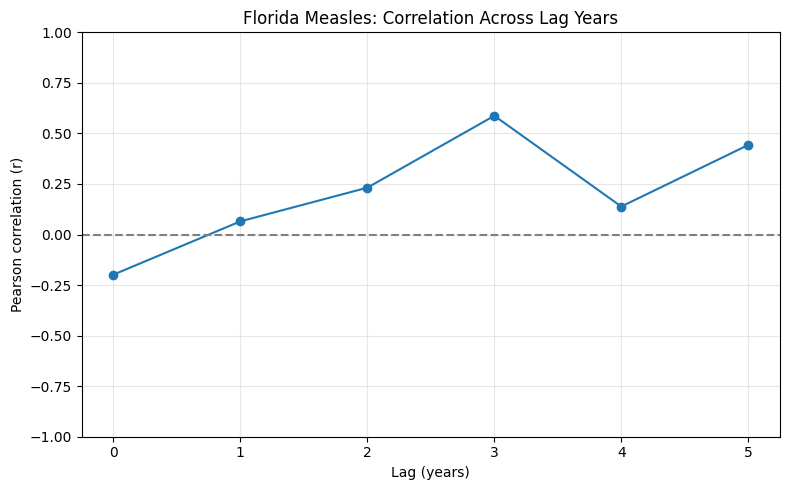

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    florida_lag_results_df["lag_years"],
    florida_lag_results_df["pearson_r"],
    marker="o"
)

ax.axhline(0, color="gray", linestyle="--")

ax.set_title("Florida Measles: Correlation Across Lag Years")
ax.set_xlabel("Lag (years)")
ax.set_ylabel("Pearson correlation (r)")
ax.set_xticks(range(6))
ax.set_ylim(-1, 1)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

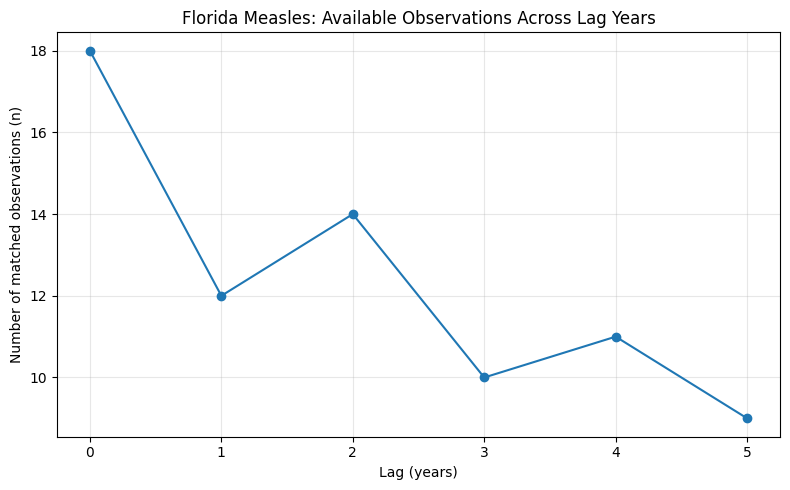

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    florida_lag_results_df["lag_years"],
    florida_lag_results_df["n"],
    marker="o"
)

plt.title("Florida Measles: Available Observations Across Lag Years")
plt.xlabel("Lag (years)")
plt.ylabel("Number of matched observations (n)")
plt.xticks(range(6))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# Create Florida canonical analytical dataset
florida_canonical = florida_analysis[
    [
        "year",
        "state",
        "measles_coverage_pct",
        "measles_cases_per_100k"
    ]
].copy()

florida_canonical = (
    florida_canonical
    .sort_values("year")
    .reset_index(drop=True)
)

# Identify consecutive calendar years
florida_canonical["consecutive_year"] = (
    florida_canonical["year"].diff() == 1
)

# Calculate year-to-year changes
florida_canonical["coverage_change"] = (
    florida_canonical["measles_coverage_pct"].diff()
)

florida_canonical["incidence_change"] = (
    florida_canonical["measles_cases_per_100k"].diff()
)

# Do not calculate changes across missing-year gaps
florida_canonical.loc[
    ~florida_canonical["consecutive_year"],
    ["coverage_change", "incidence_change"]
] = np.nan

# Match California's column order
florida_canonical = florida_canonical[
    [
        "year",
        "state",
        "measles_coverage_pct",
        "measles_cases_per_100k",
        "coverage_change",
        "incidence_change",
        "consecutive_year"
    ]
]

print("FLORIDA CANONICAL ANALYTICAL DATASET")
print("Rows:", len(florida_canonical))
display(florida_canonical)

FLORIDA CANONICAL ANALYTICAL DATASET
Rows: 18


,year,state,measles_coverage_pct,measles_cases_per_100k,coverage_change,incidence_change,consecutive_year
0,1995,FL,90.59,0.061907,NaN,NaN,False
1,1996,FL,89.86,0.006732,-0.73,-0.055175,True
2,1997,FL,90.55,0.046094,0.69,0.039362,True
3,1998,FL,92.74,0.012914,2.19,-0.033180,True
4,1999,FL,91.94,0.012691,-0.80,-0.000224,True
5,2000,FL,89.15,0.012463,-2.79,-0.000228,True
6,2002,FL,91.36,0.011984,NaN,NaN,False
7,2004,FL,96.14,0.005742,NaN,NaN,False
8,2006,FL,93.27,0.022018,NaN,NaN,False
9,2007,FL,92.73,0.027221,-0.54,0.005204,True


In [11]:
# Save Florida canonical analytical dataset
florida_canonical.to_csv(
    "florida_measles_analysis.csv",
    index=False
)

# Prepare Florida lag-results table
florida_analysis_results = florida_lag_results_df.copy()

florida_analysis_results.insert(0, "state", "FL")
florida_analysis_results.insert(1, "disease", "measles")
florida_analysis_results.insert(2, "outcome", "incidence_per_100k")

florida_analysis_results["significant_0_05"] = (
    florida_analysis_results["p_value"] < 0.05
)

# Save lag-results CSV
florida_analysis_results.to_csv(
    "florida_measles_lag_results.csv",
    index=False
)

print("Saved: florida_measles_analysis.csv")
print("Saved: florida_measles_lag_results.csv")

display(florida_analysis_results)

Saved: florida_measles_analysis.csv
Saved: florida_measles_lag_results.csv


,state,disease,outcome,lag_years,pearson_r,p_value,n,significant_0_05
0,FL,measles,incidence_per_100k,0,-0.198509,0.429735,18,False
1,FL,measles,incidence_per_100k,1,0.065155,0.840562,12,False
2,FL,measles,incidence_per_100k,2,0.231677,0.425469,14,False
3,FL,measles,incidence_per_100k,3,0.587295,0.074236,10,False
4,FL,measles,incidence_per_100k,4,0.138479,0.684701,11,False
5,FL,measles,incidence_per_100k,5,0.442850,0.232573,9,False
